# 03 — Figure Making

Assemble publication-quality multi-panel figures from saved results.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline

from src.config import load_config
from src.data_io import load_results
from src import visualization as viz
from src import utils

cfg = load_config()

# Load previously saved results (run batch_process_slices.py first)
results_dir = cfg['paths']['results_dir']
try:
    summary_df = load_results(os.path.join(results_dir, 'all_summaries.csv'))
    print(f'Loaded {len(summary_df)} rows')
except FileNotFoundError:
    print('Run scripts/batch_process_slices.py first to generate results.')
    summary_df = pd.DataFrame()


Loaded 9 rows


## Up/Down state metrics

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\fig1_overview_metrics.pdf


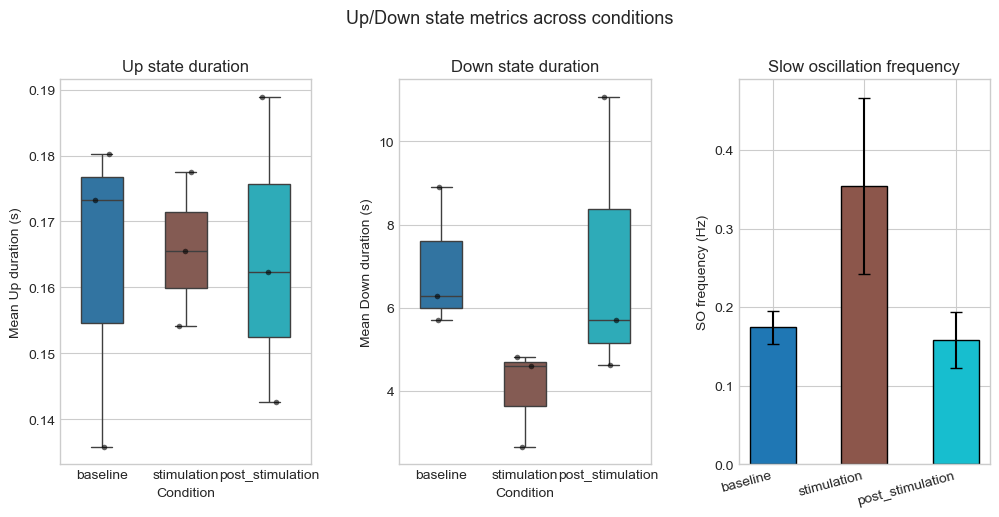

In [3]:
if not summary_df.empty:
    fig = plt.figure(figsize=(12, 5))
    gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)

    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])
    ax3 = fig.add_subplot(gs[2])

    viz.plot_duration_boxplot(summary_df, 'up',   cfg, ax=ax1)
    viz.plot_duration_boxplot(summary_df, 'down', cfg, ax=ax2)
    viz.plot_so_frequency(summary_df, cfg, ax=ax3)

    fig.suptitle('Up/Down state metrics across conditions', fontsize=13, y=1.02)

    # Save
    viz.save_figure(fig, 'fig1_overview_metrics', cfg)
    plt.show()


## Delta duration

Trial IDs found:
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01  →  ['baseline', 'post_stimulation', 'stimulation']
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02  →  ['baseline', 'post_stimulation', 'stimulation']
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03  →  ['baseline', 'post_stimulation', 'stimulation']

stimulation vs baseline: 3 paired trial(s)

post_stimulation vs baseline: 3 paired trial(s)
[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\fig2_delta_duration.pdf


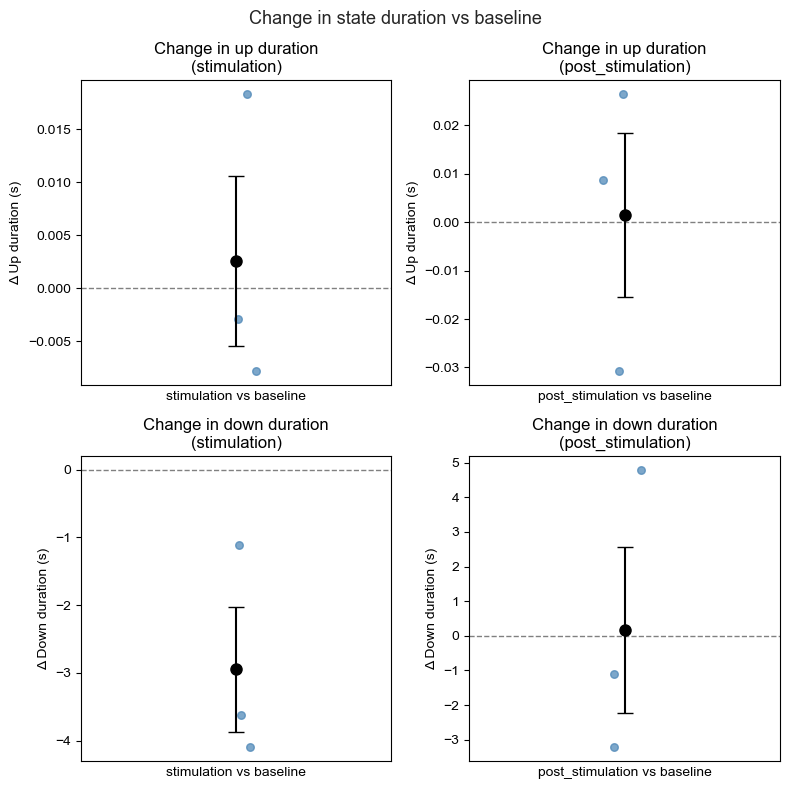

In [ ]:
from src.utils import parse_trial_id


if not summary_df.empty:
    baseline_cond    = cfg.get('baseline_condition', cfg['conditions'][0])
    comparison_conds = [c for c in cfg['conditions'] if c != baseline_cond]
    all_conditions   = cfg['conditions']

    # Add a trial_id column by stripping the condition suffix from slice_id
    summary_df['trial_id'] = summary_df['slice_id'].apply(
        lambda s: parse_trial_id(s, all_conditions)
    )

    print('Trial IDs found:')
    for tid in sorted(summary_df['trial_id'].unique()):
        conds_present = summary_df[summary_df['trial_id'] == tid]['condition'].tolist()
        print(f'  {tid}  →  {conds_present}')

    # Build delta values by joining on trial_id
    n_cols = len(comparison_conds)
    fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 8))
    if n_cols == 1:
        axes = axes.reshape(2, 1)

    for col_i, comp_cond in enumerate(comparison_conds):
        delta_up, delta_down = [], []

        for trial_id in summary_df['trial_id'].unique():
            trial_rows = summary_df[summary_df['trial_id'] == trial_id]

            bl_rows   = trial_rows[trial_rows['condition'] == baseline_cond]
            comp_rows = trial_rows[trial_rows['condition'] == comp_cond]

            # Skip if either side is missing for this trial
            if bl_rows.empty or comp_rows.empty:
                continue

            bl_up    = bl_rows['mean_up_s'].values[0]
            bl_down  = bl_rows['mean_down_s'].values[0]
            comp_up   = comp_rows['mean_up_s'].values[0]
            comp_down = comp_rows['mean_down_s'].values[0]

            # Skip if any value is NaN
            if any(np.isnan(v) for v in [bl_up, bl_down, comp_up, comp_down]):
                continue

            delta_up.append(float(comp_up   - bl_up))
            delta_down.append(float(comp_down - bl_down))

        print(f'\n{comp_cond} vs {baseline_cond}: {len(delta_up)} paired trial(s)')

        viz.plot_delta_duration(delta_up,   comp_cond, 'up',   cfg, ax=axes[0, col_i])
        viz.plot_delta_duration(delta_down, comp_cond, 'down', cfg, ax=axes[1, col_i])

    fig.suptitle('Change in state duration vs baseline', fontsize=13)
    plt.tight_layout()
    viz.save_figure(fig, 'fig2_delta_duration', cfg)
    plt.show()


## Delta duration (cool plot version)

stimulation vs baseline: 3 paired trial(s)
post_stimulation vs baseline: 3 paired trial(s)


C:\Users\leosp\AppData\Local\Temp\ipykernel_4796\1336830773.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\fig_joint_delta_combined.pdf


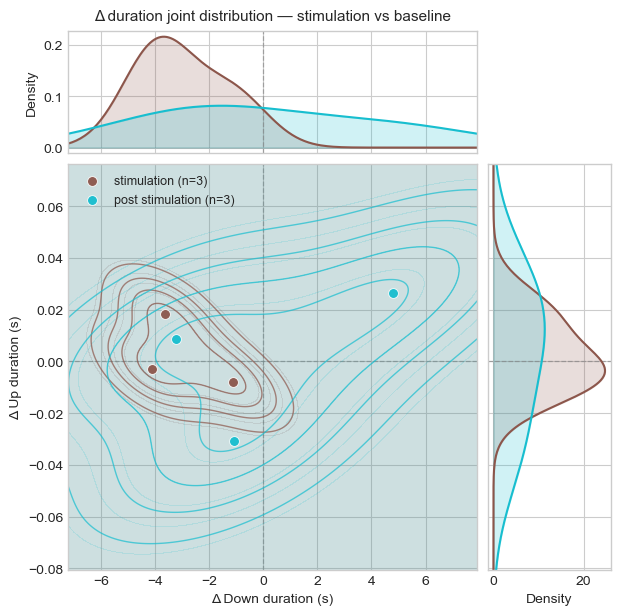

In [2]:
# ---------------------------------------------------------------------------
# Joint Δup / Δdown scatter + KDE — all comparison conditions overlaid
# ---------------------------------------------------------------------------

from src.utils import parse_trial_id

if not summary_df.empty:
    baseline_cond    = cfg.get('baseline_condition', cfg['conditions'][0])
    comparison_conds = [c for c in cfg['conditions'] if c != baseline_cond]
    all_conditions   = cfg['conditions']

    if 'trial_id' not in summary_df.columns:
        summary_df['trial_id'] = summary_df['slice_id'].apply(
            lambda s: parse_trial_id(s, all_conditions)
        )

    # Collect paired deltas for every comparison condition
    delta_data = {}   # {condition_label: (delta_up_list, delta_down_list)}

    for comp_cond in comparison_conds:
        delta_up, delta_down = [], []

        for trial_id in summary_df['trial_id'].unique():
            trial_rows = summary_df[summary_df['trial_id'] == trial_id]

            bl_rows   = trial_rows[trial_rows['condition'] == baseline_cond]
            comp_rows = trial_rows[trial_rows['condition'] == comp_cond]

            if bl_rows.empty or comp_rows.empty:
                continue

            bl_up     = bl_rows['mean_up_s'].values[0]
            bl_down   = bl_rows['mean_down_s'].values[0]
            comp_up   = comp_rows['mean_up_s'].values[0]
            comp_down = comp_rows['mean_down_s'].values[0]

            if any(np.isnan(v) for v in [bl_up, bl_down, comp_up, comp_down]):
                continue

            delta_up.append(float(comp_up   - bl_up))
            delta_down.append(float(comp_down - bl_down))

        print(f"{comp_cond} vs {baseline_cond}: {len(delta_up)} paired trial(s)")
        delta_data[comp_cond] = (delta_up, delta_down)

    fig = viz.plot_delta_duration_joint(
        delta_data = delta_data,
        cfg        = cfg,
    )

    plt.tight_layout()
    viz.save_figure(fig, 'fig_joint_delta_combined', cfg)
    plt.show()

## Up-Down state detection (binomial not so binomial)

In [8]:
from src.data_io import list_h5_files

h5_files = list_h5_files(cfg['paths']['condition_dir'])
print("Available files:")
for f in h5_files:
    print(" ", os.path.basename(f))

Available files:
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_baseline.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_post_stimulation.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_stimulation.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_baseline.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_stimulation.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_baseline.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_post_stimulation.h5
  20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_stimulation.h5


In [5]:
H5_FILENAME = '20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation.h5'

[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation | baseline] Running full analysis...
  Loaded 312500 samples × 32 channels @ 3125.0000000000005 Hz
  Features extracted: shape (99800, 3), downsampled to 1000.0 Hz
  State detection: 16 Up states, 17 Down states (threshold = 2.929)
  Firing rates: mean Up FR = 3.839, mean Down FR = 2.905
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation | baseline] Done. Detected 16 Up states, 17 Down states.
[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\fig3_example_20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation.pdf


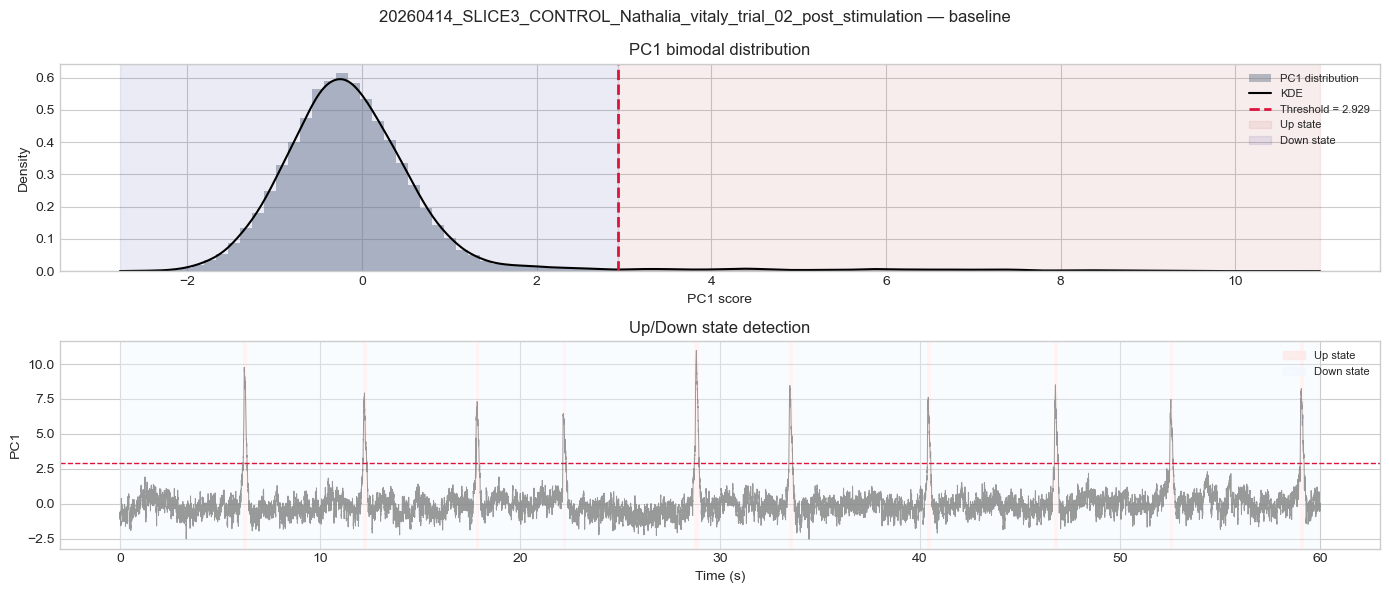

In [6]:
from src.core.experiment import Experiment
from src.data_io import list_h5_files

h5_files = list_h5_files(cfg['paths']['condition_dir'])

if h5_files:
    EXAMPLE_SLICE     = rf"C:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\data\condition\{H5_FILENAME}"
    EXAMPLE_CONDITION = cfg['conditions'][0]

    exp = Experiment(EXAMPLE_SLICE, condition=EXAMPLE_CONDITION, cfg=cfg)
    exp.run()

    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=False)

    viz.plot_pc1_distribution(exp.pc1, exp.threshold, cfg, ax=axes[0])
    viz.plot_states_overlay(exp.t_ds, exp.pc1, exp.states,
                             exp.threshold, cfg, t_range_s=(0, 60), ax=axes[1])
    fig.suptitle(f'{exp.slice_id} — {EXAMPLE_CONDITION}', fontsize=12)
    plt.tight_layout()
    viz.save_figure(fig, f'fig3_example_{exp.slice_id}', cfg)
    plt.show()
else:
    print('No .h5 files found. Add recordings to data/processed/')

## Up-State Raster plot

[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation | baseline] Running full analysis...
  Loaded 312500 samples × 32 channels @ 3125.0000000000005 Hz
  Features extracted: shape (99800, 3), downsampled to 1000.0 Hz
  State detection: 16 Up states, 17 Down states (threshold = 2.929)
  Firing rates: mean Up FR = 3.839, mean Down FR = 2.905
[20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation | baseline] Done. Detected 16 Up states, 17 Down states.

Slice    : 20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation
Condition: baseline
Up states: 16
Window   : ±1.5 s around each peak
Baseline : 0.3 s pre-peak
[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\raster_up_fr_20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation_baseline.pdf


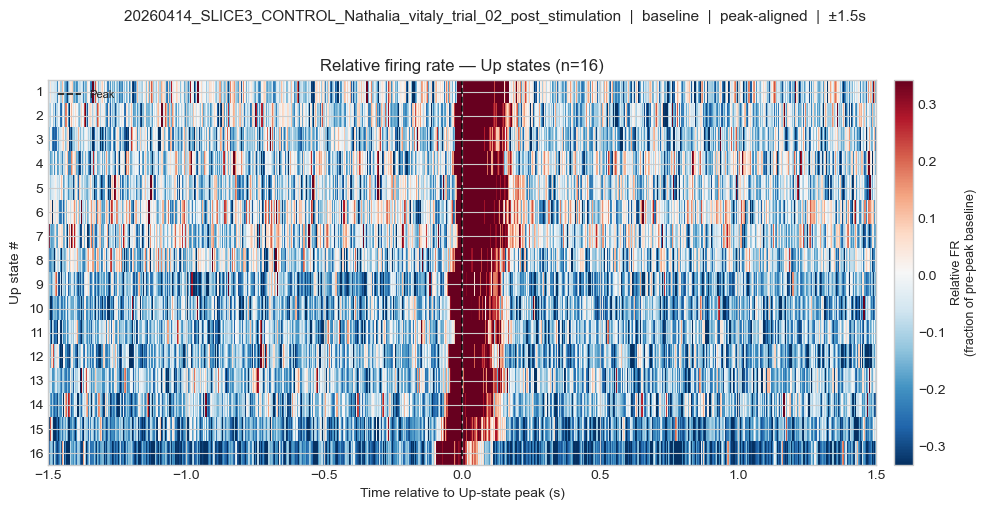

In [9]:
# ---------------------------------------------------------------------------
# Up-state firing rate raster — peak-aligned, relative FR
#
# Colour = (logMUA(t) - pre_peak_baseline) / |pre_peak_baseline|
#   0  = no change from the pre-peak firing level
#  +1  = firing doubled relative to pre-peak
# Rows sorted by peak relative FR (strongest Up states on top).
# ---------------------------------------------------------------------------

from src.core.experiment import Experiment
import copy

H5_PATH   = rf"C:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\data\condition\{H5_FILENAME}"
CONDITION = cfg['conditions'][0]         # e.g. 'baseline'
WINDOW_S  = 1.5                   # ± seconds around each Up-state PEAK
PRE_BASELINE_S = 0.3              # seconds before peak used as FR baseline

cfg_local = copy.deepcopy(cfg)
cfg_local['firing_rates']['alignment_window_s'] = WINDOW_S

exp = Experiment(H5_PATH, condition=CONDITION, cfg=cfg_local)
exp.run()

print(f"\nSlice    : {exp.slice_id}")
print(f"Condition: {CONDITION}")
print(f"Up states: {exp.n_up}")
print(f"Window   : ±{WINDOW_S} s around each peak")
print(f"Baseline : {PRE_BASELINE_S} s pre-peak")
fig, ax = viz.plot_up_state_raster(
    up_traces      = exp.up_traces,
    t_win          = exp.t_win,
    epochs         = exp.epochs,
    log_mua_raw    = exp.log_mua_raw,
    t_ds           = exp.t_ds,
    cfg            = cfg_local,
    sort_by_peak_fr  = True,      # False → chronological order
    pre_baseline_s   = PRE_BASELINE_S,
    vmin             = None,      # None → auto
    vmax             = None,      # None → auto
)

fig.suptitle(
    f"{exp.slice_id}  |  {CONDITION}  |  peak-aligned  |  ±{WINDOW_S}s",
    fontsize=11, y=1.01
)
plt.tight_layout()
viz.save_figure(fig, f'raster_up_fr_{exp.slice_id}_{CONDITION}', cfg_local)
plt.show()

## Big spectrogram

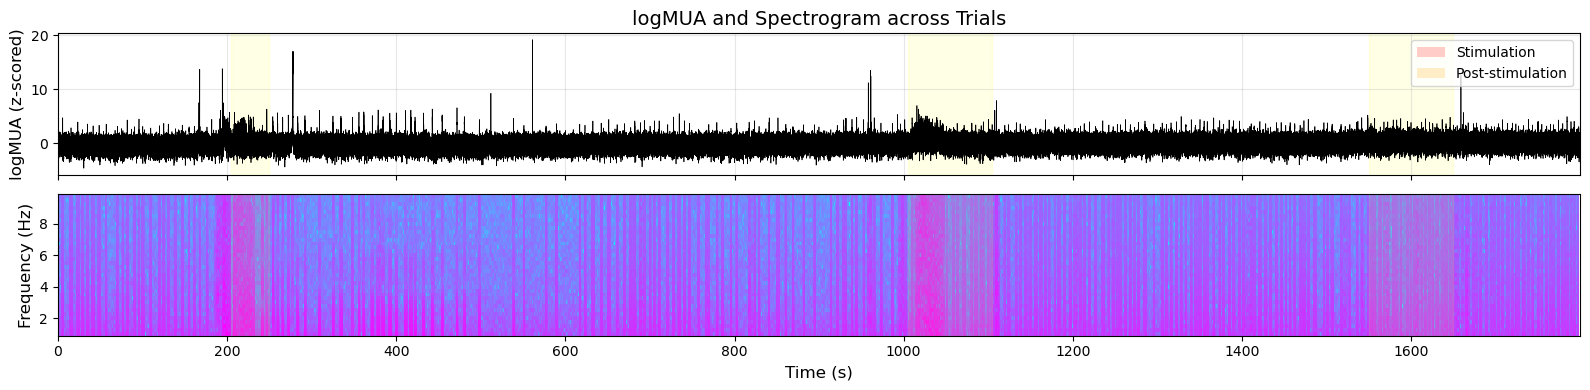

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import signal

from src.preprocessing import extract_features
from src.data_io import load_h5
from src.visualization import plot_spectrogram
from src.utils import spectrogram

H5_FILENAME = '20260414_SLICE3_CONTROL_Nathalia'

# Load your data
h5_path = rf"C:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\data\processed\{H5_FILENAME}.h5"
json_path = rf"C:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\data\condition\{H5_FILENAME}_trial_definitions.json"

data, meta = load_h5(h5_path)
fs = meta["fs"]

with open(json_path, 'r') as f:
    trials = json.load(f)

# Extract global time window
trial_start_s = trials[0]["start_s"]
trial_end_s = trials[-1]["end_s"]
trial_start_idx = int(trial_start_s * fs)
trial_end_idx = int(trial_end_s * fs)

# Slice data for the full duration
data_slice = data[trial_start_idx:trial_end_idx, :]
lfp_signal = data_slice.mean(axis=1)  # Average across channels

# Extract features (SO, gamma envelope, logMUA) using extract_features
features, t_ds = extract_features(lfp_signal, fs, cfg["preprocessing"])

# logMUA is column 2
log_mua = features[:, 2]

freqs, times, Sxx_db = spectrogram(lfp_signal, fs)

plot_spectrogram(log_mua, times, freqs, Sxx_db, t_ds, trials, trial_start_s)

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\fig_delta_fr_up.pdf


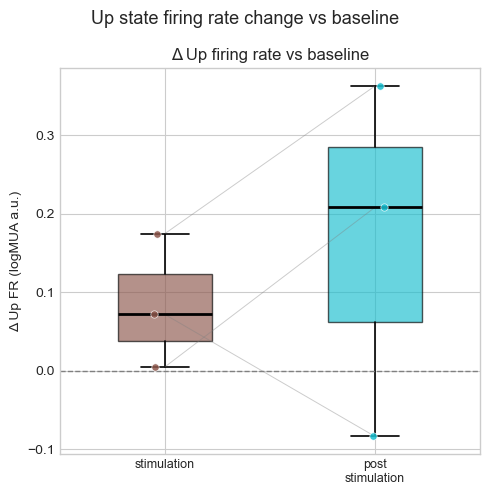

[viz] Saved figure → c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\results/figures\fig_delta_fr_down.pdf


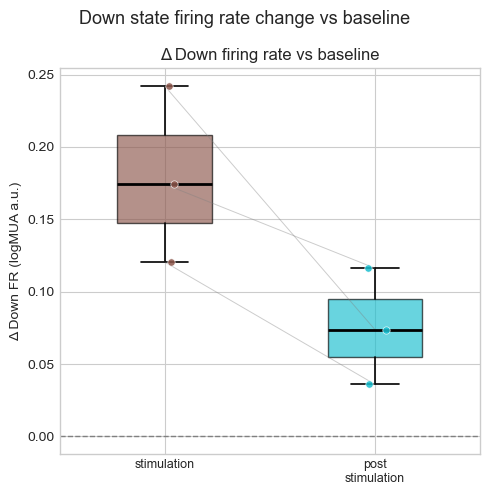


Up FR deltas:
  stimulation: n=3, mean=0.084, SEM=0.049
  post_stimulation: n=3, mean=0.162, SEM=0.131

Down FR deltas:
  stimulation: n=3, mean=0.179, SEM=0.035
  post_stimulation: n=3, mean=0.075, SEM=0.023


In [2]:
# ---------------------------------------------------------------------------
# Figure — Delta firing rate boxplots (Up and Down, paired across conditions)
#
# One figure per state:
#   Fig A — Up FR:   [stimulation Δ] [post_stimulation Δ]
#   Fig B — Down FR: [stimulation Δ] [post_stimulation Δ]
#
# Points from the same trial are connected by a thin grey line.
# ---------------------------------------------------------------------------

if not summary_df.empty:
    import re

    def parse_trial_id(slice_id, conditions):
        for cond in sorted(conditions, key=len, reverse=True):
            pattern = r'[_\-]' + re.escape(cond) + r'$'
            stripped = re.sub(pattern, '', slice_id, flags=re.IGNORECASE)
            if stripped != slice_id:
                return stripped
        return slice_id

    baseline_cond    = cfg.get('baseline_condition', cfg['conditions'][0])
    comparison_conds = [c for c in cfg['conditions'] if c != baseline_cond]
    all_conditions   = cfg['conditions']

    if 'trial_id' not in summary_df.columns:
        summary_df['trial_id'] = summary_df['slice_id'].apply(
            lambda s: parse_trial_id(s, all_conditions)
        )

    missing = [c for c in ['mean_fr_up', 'mean_fr_down']
               if c not in summary_df.columns]
    if missing:
        print(f"Missing columns: {missing}. Re-run batch_process_slices.py.")
    else:
        # Collect paired Δ values for every comparison condition
        # delta_up  = {"stimulation": [...], "post_stimulation": [...]}
        delta_up   = {c: [] for c in comparison_conds}
        delta_down = {c: [] for c in comparison_conds}

        # Iterate over trials that have ALL conditions present so that
        # the connecting lines actually represent true pairs
        trial_ids = summary_df['trial_id'].unique()

        for trial_id in trial_ids:
            trial_rows = summary_df[summary_df['trial_id'] == trial_id]

            bl_rows = trial_rows[trial_rows['condition'] == baseline_cond]
            if bl_rows.empty:
                continue

            bl_fr_up   = bl_rows['mean_fr_up'].values[0]
            bl_fr_down = bl_rows['mean_fr_down'].values[0]

            if np.isnan(bl_fr_up) or np.isnan(bl_fr_down):
                continue

            for comp_cond in comparison_conds:
                comp_rows = trial_rows[trial_rows['condition'] == comp_cond]
                if comp_rows.empty:
                    delta_up[comp_cond].append(np.nan)   # keep index aligned
                    delta_down[comp_cond].append(np.nan)
                    continue

                comp_fr_up   = comp_rows['mean_fr_up'].values[0]
                comp_fr_down = comp_rows['mean_fr_down'].values[0]

                delta_up[comp_cond].append(
                    float(comp_fr_up   - bl_fr_up)   if not np.isnan(comp_fr_up)   else np.nan
                )
                delta_down[comp_cond].append(
                    float(comp_fr_down - bl_fr_down) if not np.isnan(comp_fr_down) else np.nan
                )

        # --- Figure A: Up FR ---
        fig_up, ax_up = viz.plot_delta_fr_boxplot(delta_up, 'up', cfg)
        fig_up.suptitle('Up state firing rate change vs baseline', fontsize=13)
        plt.tight_layout()
        viz.save_figure(fig_up, 'fig_delta_fr_up', cfg)
        plt.show()

        # --- Figure B: Down FR ---
        fig_down, ax_down = viz.plot_delta_fr_boxplot(delta_down, 'down', cfg)
        fig_down.suptitle('Down state firing rate change vs baseline', fontsize=13)
        plt.tight_layout()
        viz.save_figure(fig_down, 'fig_delta_fr_down', cfg)
        plt.show()

        # Print summary
        for state_label, dd in [('Up', delta_up), ('Down', delta_down)]:
            print(f"\n{state_label} FR deltas:")
            for cond, vals in dd.items():
                clean = [v for v in vals if not np.isnan(v)]
                if clean:
                    print(f"  {cond}: n={len(clean)}, "
                          f"mean={np.mean(clean):.3f}, "
                          f"SEM={np.std(clean, ddof=1)/np.sqrt(len(clean)):.3f}")